# BlackLegend — Entregable II (parte 1): entrenamiento y evaluación de modelos
**Modelos y Simulación de Sistemas II — Universidad de Antioquia**
Bryan David Molina · David Julian Penagos · Xiomara Giraldo Pérez

Este notebook reproduce la Sección III de configuración experimental y resultados del entrenamiento:

1. Partición de los datos y metodología de validación.
2. Tratamiento del desbalance de clases (experimento de control).
3. Malla de hiperparámetros de los seis modelos comparados.
4. Efecto de los hiperparámetros (curvas de entrenamiento y validación).
5. Resultados de entrenamiento, validación y prueba con intervalos de confianza.
6. Comparación de los escenarios A (sin variables redundantes) y B (todas las variables).

**Convención:** la clase positiva es el **incumplimiento** (`y = 1 - loan_paid_back`), porque es el evento que interesa detectar.

Tiempo de ejecución aproximado: 30–45 minutos en un equipo de 2 núcleos. Los resultados se guardan en `resultados/` y las figuras en `figs/`.

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     GridSearchCV, cross_val_predict, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix)
from imblearn.pipeline import Pipeline as PipelineImb
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True); os.makedirs('resultados', exist_ok=True)

SEMILLA = 42
N_JOBS = 2
# Paleta categórica fija: cada modelo conserva su color en todas las figuras
COLOR = {'LR': '#2a78d6', 'k-NN': '#eb6834', 'RF': '#1baf7a', 'GB': '#eda100', 'SVM': '#e87ba4', 'MLP': '#6250d6'}
GRIS = '#52514e'
ESTILO = {'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'font.size': 7.5, 'axes.spines.top': False,
          'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 8,
          'legend.fontsize': 6.5, 'legend.frameon': False, 'lines.linewidth': 1.4}
ANCHO1, ANCHO2 = 3.4, 7.1   # ancho de una y dos columnas IEEE (pulgadas)

def ic95(v):
    """Semiancho del intervalo de confianza del 95 % de la media (t de Student, n-1 grados de libertad)."""
    v = np.asarray(v, dtype=float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))

coma = lambda v, d=3: f'{v:.{d}f}'.replace('.', ',')
FMT_COMA = matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))

## 1. Datos, preprocesamiento y partición

- `monthly_income` se elimina porque es `annual_income / 12`.
- **Escenario A (principal):** se excluyen `grade_subgrade`, `interest_rate` e `installment`. Son condiciones que la entidad fija *después* de evaluar al solicitante y, además, son redundantes: la letra del grado es una discretización exacta de `credit_score` y la cuota se obtiene con la fórmula de amortización a partir de monto, tasa y plazo (se verifica abajo).
- **Escenario B (referencia):** todas las variables, con `grade_subgrade` codificada de forma ordinal (A1 = 0, …, F5 = 29).
- Variables nominales con *One-Hot Encoding*; numéricas estandarizadas. Todo el preprocesamiento va dentro de un `Pipeline`, de modo que el escalador se ajusta únicamente con los datos de entrenamiento de cada pliegue.

In [2]:
df = pd.read_csv('loan_dataset_20000.csv')
y = (1 - df['loan_paid_back']).rename('incumplimiento')      # 1 = incumplió (clase positiva)

# Verificación de las redundancias que justifican el escenario A
letra = df['grade_subgrade'].str[0]
print('Rango de credit_score por letra del grado (no se solapan):')
print(df.groupby(letra)['credit_score'].agg(['min', 'max']).T.to_string())
r, n = df['interest_rate'] / 1200, df['loan_term']
cuota = df['loan_amount'] * r / (1 - (1 + r) ** -n)
print(f"\nDiferencia máxima entre installment y la fórmula de amortización: {(cuota - df['installment']).abs().max():.3f}")

nominales = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']
redundantes = ['grade_subgrade', 'interest_rate', 'installment']
numericas_A = [c for c in df.columns if c not in nominales + redundantes + ['monthly_income', 'loan_paid_back']]
orden_grade = [f'{g}{i}' for g in 'ABCDEF' for i in range(1, 6)]
df['grade_ord'] = df['grade_subgrade'].map({k: i for i, k in enumerate(orden_grade)})
numericas_B = numericas_A + ['interest_rate', 'installment', 'grade_ord']

def preprocesador(numericas):
    return ColumnTransformer([('num', StandardScaler(), numericas),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominales)])

X_A, X_B = df[numericas_A + nominales], df[numericas_B + nominales]
idx_train, idx_test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=SEMILLA)
Xtr, Xte, ytr, yte = X_A.loc[idx_train], X_A.loc[idx_test], y.loc[idx_train], y.loc[idx_test]
print(f'\nEntrenamiento: {len(Xtr)} muestras ({ytr.mean():.1%} incumplimiento) | Prueba: {len(Xte)} muestras ({yte.mean():.1%} incumplimiento)')
print('Variables de entrada, escenario A:', preprocesador(numericas_A).fit(Xtr).transform(Xtr[:1]).shape[1])
print('Variables de entrada, escenario B:', preprocesador(numericas_B).fit(X_B.loc[idx_train]).transform(X_B.loc[idx_train][:1]).shape[1])

Rango de credit_score por letra del grado (no se solapan):
grade_subgrade    A    B    C    D    E    F
min             800  740  670  610  580  373
max             850  799  739  669  609  579

Diferencia máxima entre installment y la fórmula de amortización: 0.005

Entrenamiento: 16000 muestras (20.0% incumplimiento) | Prueba: 4000 muestras (20.0% incumplimiento)
Variables de entrada, escenario A: 37
Variables de entrada, escenario B: 40


**Metodología de validación.**
- *Hold-out* estratificado 80/20: el conjunto de prueba (4.000 muestras) no se usa en ninguna decisión; solo para el reporte final.
- Sobre el 80 % de entrenamiento (16.000 muestras): **validación cruzada estratificada de 5 pliegues repetida 2 veces** (10 estimaciones por configuración). Con ella se seleccionan los hiperparámetros y se calculan los intervalos de confianza del 95 % (t de Student con 9 grados de libertad).
- Los intervalos en prueba se calculan con *bootstrap* (1.000 remuestreos del conjunto de prueba).

In [3]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEMILLA)
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # predicciones fuera de pliegue para fijar el umbral

## 2. Tratamiento del desbalance (experimento de control)

La proporción es 80/20. Antes de fijar la metodología se comparan cuatro estrategias con dos modelos de referencia: no hacer nada, ponderar las clases (`class_weight='balanced'`), submuestreo aleatorio (RUS) y SMOTE. El remuestreo va dentro del `Pipeline` de `imblearn`, así que solo afecta a los pliegues de entrenamiento.

In [4]:
def con_estrategia(nombre, modelo):
    pasos = [('prep', preprocesador(numericas_A))]
    if nombre == 'RUS': pasos.append(('muestreo', RandomUnderSampler(random_state=SEMILLA)))
    if nombre == 'SMOTE': pasos.append(('muestreo', SMOTE(random_state=SEMILLA)))
    if nombre == 'Ponderación de clases': modelo.set_params(class_weight='balanced')
    return PipelineImb(pasos + [('clf', modelo)])

filas = []
for nombre_m, fabrica in [('LR', lambda: LogisticRegression(max_iter=2000)),
                          ('GB', lambda: HistGradientBoostingClassifier(random_state=SEMILLA))]:
    for estrategia in ['Sin tratamiento', 'Ponderación de clases', 'RUS', 'SMOTE']:
        r = cross_validate(con_estrategia(estrategia, fabrica()), Xtr, ytr, cv=cv, n_jobs=N_JOBS,
                           scoring={'auc': 'roc_auc', 'ap': 'average_precision'})
        filas.append({'modelo': nombre_m, 'estrategia': estrategia, 'AUC': r['test_auc'].mean(), 'IC AUC': ic95(r['test_auc']),
                      'AP': r['test_ap'].mean(), 'IC AP': ic95(r['test_ap'])})
desbalance = pd.DataFrame(filas)
desbalance.to_csv('resultados/desbalance.csv', index=False)
desbalance.round(4)

,modelo,estrategia,AUC,IC AUC,AP,IC AP
0,LR,Sin tratamiento,0.8840,0.0057,0.7682,0.0086
1,LR,Ponderación de clases,0.8844,0.0056,0.7669,0.0087
2,LR,RUS,0.8841,0.0056,0.7659,0.0090
3,LR,SMOTE,0.8829,0.0057,0.7646,0.0090
4,GB,Sin tratamiento,0.8896,0.0062,0.7818,0.0088
5,GB,Ponderación de clases,0.8892,0.0056,0.7815,0.0085
6,GB,RUS,0.8851,0.0067,0.7754,0.0098
7,GB,SMOTE,0.8875,0.0051,0.7796,0.0074


Ninguna estrategia de remuestreo mejora el AUC ni la precisión media (AP): las diferencias son menores que el intervalo de confianza. Por eso **no se remuestrean los datos**: se entrena con la distribución original (probabilidades mejor calibradas) y el desbalance se maneja (i) con métricas que no dependen de la clase mayoritaria y (ii) ajustando el **umbral de decisión** con las predicciones de validación.

### Control: ¿hace falta una transformación logarítmica?

Las variables monetarias tienen asimetría positiva fuerte (2,3 a 2,8). Se compara la estandarización simple contra `log(1 + x)` seguido de estandarización en tres modelos sensibles a la escala.

In [5]:
monetarias = ['annual_income', 'total_credit_limit', 'current_balance', 'loan_amount']
otras = [c for c in numericas_A if c not in monetarias]
prep_log = ColumnTransformer([('log', Pipeline([('log', FunctionTransformer(np.log1p)), ('esc', StandardScaler())]), monetarias),
                              ('num', StandardScaler(), otras),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominales)])
filas = []
for nombre_m, fabrica in [('LR', lambda: LogisticRegression(max_iter=2000)), ('k-NN', lambda: KNeighborsClassifier(n_neighbors=101)),
                          ('MLP', lambda: MLPClassifier((32,), early_stopping=True, random_state=SEMILLA))]:
    a = cross_validate(Pipeline([('prep', preprocesador(numericas_A)), ('clf', fabrica())]), Xtr, ytr, cv=cv, scoring='roc_auc', n_jobs=N_JOBS)['test_score']
    b = cross_validate(Pipeline([('prep', prep_log), ('clf', fabrica())]), Xtr, ytr, cv=cv, scoring='roc_auc', n_jobs=N_JOBS)['test_score']
    filas.append({'modelo': nombre_m, 'AUC estandarización': a.mean(), 'AUC log + estandarización': b.mean(), 'diferencia': (b - a).mean(), 'IC dif.': ic95(b - a)})
control_log = pd.DataFrame(filas); control_log.to_csv('resultados/control_log.csv', index=False)
control_log.round(4)

,modelo,AUC estandarización,AUC log + estandarización,diferencia,IC dif.
0,LR,0.8840,0.8840,-0.0000,0.0002
1,k-NN,0.8365,0.8352,-0.0013,0.0022
2,MLP,0.8851,0.8843,-0.0008,0.0038


La diferencia es menor que su intervalo de confianza en los tres modelos (las variables monetarias casi no aportan a la predicción), así que se conserva solo la estandarización.

## 3. Modelos y malla de hiperparámetros

| Requisito de la guía | Modelo |
|---|---|
| Paramétrico | Regresión logística (LR) |
| No paramétrico | k vecinos más cercanos (k-NN) |
| Ensamble de árboles | Random Forest (RF) y Gradient Boosting (GB, `HistGradientBoostingClassifier`) |
| Máquina de vectores de soporte | SVM (kernel lineal y RBF) |
| Red neuronal | Perceptrón multicapa (MLP) |

El criterio de selección es el **AUC-ROC medio de validación**.

In [6]:
MODELOS = {
    'LR': (LogisticRegression(solver='liblinear', max_iter=2000),
           {'clf__penalty': ['l1', 'l2'], 'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}),
    'k-NN': (KNeighborsClassifier(),
             {'clf__n_neighbors': [5, 11, 21, 51, 101, 201, 301, 401], 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]}),
    'RF': (RandomForestClassifier(random_state=SEMILLA, n_jobs=1),
           {'clf__n_estimators': [100, 300], 'clf__max_depth': [4, 8, 12, None], 'clf__min_samples_leaf': [1, 10, 30]}),
    'GB': (HistGradientBoostingClassifier(random_state=SEMILLA),
           {'clf__learning_rate': [0.01, 0.05, 0.1, 0.3], 'clf__max_iter': [100, 300], 'clf__max_depth': [2, 3, 5, 8]}),
    'SVM': (SVC(cache_size=1000),
            [{'clf__kernel': ['rbf'], 'clf__C': [0.1, 1, 10, 100], 'clf__gamma': [0.0001, 0.001, 0.01, 0.1]},
             {'clf__kernel': ['linear'], 'clf__C': [0.01, 0.1, 1]}]),
    'MLP': (MLPClassifier(early_stopping=True, n_iter_no_change=10, max_iter=500, random_state=SEMILLA),
            {'clf__hidden_layer_sizes': [(16,), (32,), (64,), (32, 16), (64, 32)], 'clf__alpha': [0.0001, 0.01, 1.0, 10.0],
             'clf__learning_rate_init': [0.001, 0.01]}),
}

def n_config(malla):
    mallas = malla if isinstance(malla, list) else [malla]
    return sum(int(np.prod([len(v) for v in m.values()])) for m in mallas)

pd.DataFrame([{'modelo': k, 'configuraciones': n_config(m), 'ajustes (x10 pliegues)': 10 * n_config(m)} for k, (_, m) in MODELOS.items()])

,modelo,configuraciones,ajustes (x10 pliegues)
0,LR,12,120
1,k-NN,32,320
2,RF,24,240
3,GB,32,320
4,SVM,19,190
5,MLP,40,400


In [7]:
busquedas, mallas_df = {}, {}
for nombre, (modelo, malla) in MODELOS.items():
    t0 = time.time()
    gs = GridSearchCV(Pipeline([('prep', preprocesador(numericas_A)), ('clf', modelo)]), malla, cv=cv,
                      scoring={'auc': 'roc_auc', 'ap': 'average_precision'}, refit='auc',
                      return_train_score=True, n_jobs=N_JOBS)
    gs.fit(Xtr, ytr)
    busquedas[nombre] = gs
    res = pd.DataFrame(gs.cv_results_)
    res.columns = [c.replace('param_clf__', '') for c in res.columns]
    cols_val = [c for c in res.columns if c.startswith('split') and c.endswith('_test_auc')]
    cols_tr = [c for c in res.columns if c.startswith('split') and c.endswith('_train_auc')]
    res['ic_test_auc'] = res[cols_val].apply(ic95, axis=1)
    res['ic_train_auc'] = res[cols_tr].apply(ic95, axis=1)
    mallas_df[nombre] = res
    res.drop(columns='params').to_csv(f"resultados/malla_{nombre.replace('-', '')}.csv", index=False)
    mejor = {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}
    print(f'{nombre:5s} AUC val = {gs.best_score_:.4f} ± {res.loc[gs.best_index_, "ic_test_auc"]:.4f} | {mejor} | {time.time() - t0:.0f} s', flush=True)

mejores = {k: {p.replace('clf__', ''): v for p, v in gs.best_params_.items()} for k, gs in busquedas.items()}
json.dump(mejores, open('resultados/mejores_hiperparametros.json', 'w'), indent=2, default=str)

LR    AUC val = 0.8842 ± 0.0057 | {'C': 0.1, 'penalty': 'l1'} | 24 s


k-NN  AUC val = 0.8542 ± 0.0064 | {'n_neighbors': 401, 'p': 1, 'weights': 'distance'} | 713 s


RF    AUC val = 0.8799 ± 0.0050 | {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 300} | 278 s


GB    AUC val = 0.8934 ± 0.0046 | {'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 100} | 90 s


SVM   AUC val = 0.8709 ± 0.0057 | {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'} | 740 s


MLP   AUC val = 0.8884 ± 0.0056 | {'alpha': 1.0, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001} | 119 s


## 4. Efecto de los hiperparámetros 

Cada panel muestra el AUC medio de **entrenamiento** (línea punteada) y de **validación** (línea continua con su IC del 95 %) en función del hiperparámetro que más afecta a cada modelo. La separación entre ambas curvas mide el sobreajuste.

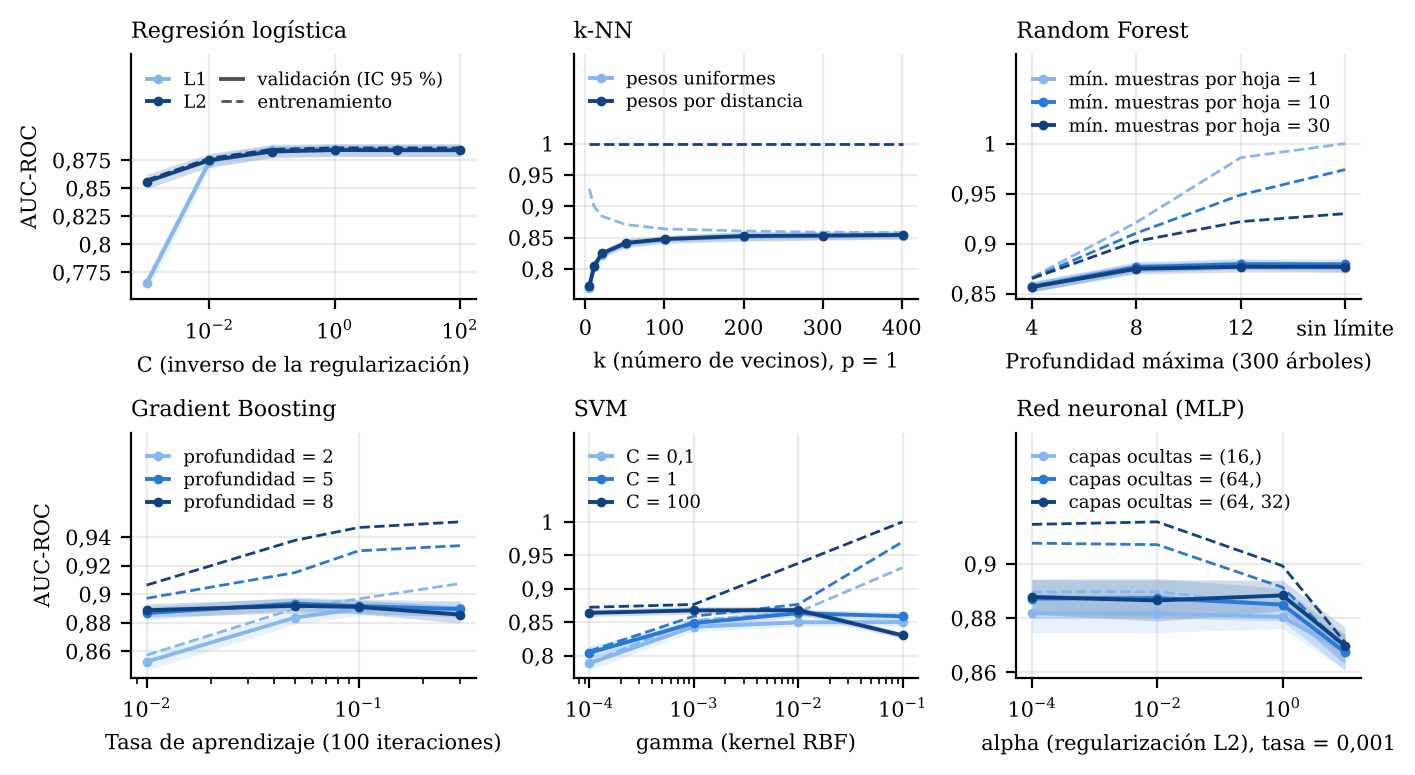

In [8]:
def igual(col, v):
    """Compara una columna de cv_results_ con un valor, sea numérico, None o una tupla."""
    if v is None:
        return col.isna() | (col.astype(str) == 'None')
    if isinstance(v, (int, float)):
        return pd.Series(np.isclose(pd.to_numeric(col, errors='coerce'), v), index=col.index)
    return col.astype(str) == str(v)

def curva(ax, res, x, filtro, etiqueta, color, xnum=None):
    d = res.copy()
    for k, v in filtro.items():
        d = d[igual(d[k], v)]
    if xnum is None:
        d = d.assign(_x=d[x].astype(float))
    else:   # eje categórico ordenado (permite el valor None = sin límite)
        d = d.assign(_x=[next(i for i, v in enumerate(xnum) if igual(pd.Series([val]), v).iloc[0]) for val in d[x]])
    d = d.sort_values('_x')
    ax.plot(d['_x'], d['mean_test_auc'], '-o', ms=2.5, color=color, label=etiqueta)
    ax.fill_between(d['_x'], d['mean_test_auc'] - d['ic_test_auc'], d['mean_test_auc'] + d['ic_test_auc'], color=color, alpha=0.18, lw=0)
    ax.plot(d['_x'], d['mean_train_auc'], '--', color=color, lw=1.0)

TONOS = ['#86b6ef', '#2a78d6', '#104281']   # un solo matiz de claro a oscuro para valores ordenados de un segundo hiperparámetro
with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(2, 3, figsize=(ANCHO2, 3.9))
    ax = axes[0, 0]; r = mallas_df['LR']
    curva(ax, r, 'C', {'penalty': 'l1'}, 'L1', TONOS[0]); curva(ax, r, 'C', {'penalty': 'l2'}, 'L2', TONOS[2])
    ax.set_xscale('log'); ax.set_xlabel('C (inverso de la regularización)'); ax.set_title('Regresión logística', loc='left')

    ax = axes[0, 1]; r = mallas_df['k-NN']; p = mejores['k-NN']['p']
    curva(ax, r, 'n_neighbors', {'p': p, 'weights': 'uniform'}, 'pesos uniformes', TONOS[0])
    curva(ax, r, 'n_neighbors', {'p': p, 'weights': 'distance'}, 'pesos por distancia', TONOS[2])
    ax.set_xlabel(f'k (número de vecinos), p = {p}'); ax.set_title('k-NN', loc='left')

    ax = axes[0, 2]; r = mallas_df['RF']; ne = mejores['RF']['n_estimators']; xn = [4, 8, 12, None]
    for hoja, c in zip([1, 10, 30], TONOS):
        curva(ax, r, 'max_depth', {'n_estimators': ne, 'min_samples_leaf': hoja}, f'mín. muestras por hoja = {hoja}', c, xnum=xn)
    ax.set_xticks(range(4)); ax.set_xticklabels(['4', '8', '12', 'sin límite'])
    ax.set_xlabel(f'Profundidad máxima ({ne} árboles)'); ax.set_title('Random Forest', loc='left')

    ax = axes[1, 0]; r = mallas_df['GB']; mi = mejores['GB']['max_iter']
    for prof, c in zip([2, 5, 8], TONOS):
        curva(ax, r, 'learning_rate', {'max_iter': mi, 'max_depth': prof}, f'profundidad = {prof}', c)
    ax.set_xscale('log'); ax.set_xlabel(f'Tasa de aprendizaje ({mi} iteraciones)'); ax.set_title('Gradient Boosting', loc='left')

    ax = axes[1, 1]; r = mallas_df['SVM']; r = r[r['kernel'].astype(str) == 'rbf']
    for C, c in zip([0.1, 1, 100], TONOS):
        curva(ax, r, 'gamma', {'C': C}, f'C = {C:g}'.replace('.', ','), c)
    ax.set_xscale('log'); ax.set_xlabel('gamma (kernel RBF)'); ax.set_title('SVM', loc='left')

    ax = axes[1, 2]; r = mallas_df['MLP']; lr = mejores['MLP']['learning_rate_init']
    for arq, c in zip([(16,), (64,), (64, 32)], TONOS):
        curva(ax, r, 'alpha', {'learning_rate_init': lr, 'hidden_layer_sizes': arq}, f'capas ocultas = {arq}', c)
    ax.set_xscale('log'); ax.set_xlabel(f'alpha (regularización L2), tasa = {lr:g}'.replace('.', ',')); ax.set_title('Red neuronal (MLP)', loc='left')

    axes[0, 0].plot([], [], '-', color=GRIS, label='validación (IC 95 %)'); axes[0, 0].plot([], [], '--', color=GRIS, lw=1.0, label='entrenamiento')
    for ax in axes.ravel():
        y0, y1 = ax.get_ylim(); marcas = [t for t in ax.get_yticks() if y0 <= t <= min(y1, 1.0)]
        ax.set_ylim(y0, y1 + 0.5 * (y1 - y0)); ax.set_yticks(marcas)      # espacio para la leyenda, sin marcas por encima de 1
        ax.legend(loc='upper left', handlelength=1.2, ncol=2 if ax is axes[0, 0] else 1, columnspacing=0.8, labelspacing=0.25)
        ax.yaxis.set_major_formatter(FMT_COMA)
    for ax in axes[:, 0]: ax.set_ylabel('AUC-ROC')
    fig.tight_layout(); fig.savefig('figs/fig5_hiperparametros.png', dpi=300, bbox_inches='tight'); plt.show()

## 5. Resultados de entrenamiento, validación y prueba

Para la mejor configuración de cada modelo:
1. **Validación:** AUC y AP medios de los 10 pliegues con su IC del 95 %.
2. **Umbral de decisión:** se obtienen predicciones fuera de pliegue (5 pliegues) sobre el conjunto de entrenamiento y se elige el umbral que maximiza el índice de Youden (sensibilidad + especificidad − 1). El conjunto de prueba no interviene.
3. **Entrenamiento y prueba:** el modelo se reajusta con las 16.000 muestras de entrenamiento y se evalúa en entrenamiento y en prueba; los IC de prueba se obtienen por *bootstrap*.

In [9]:
def puntaje(modelo, X):
    return modelo.predict_proba(X)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X)

def metricas_umbral(y_real, s, umbral):
    tn, fp, fn, tp = confusion_matrix(y_real, (s >= umbral).astype(int)).ravel()
    sens, esp = tp / (tp + fn), tn / (tn + fp)
    prec = tp / (tp + fp) if tp + fp else 0.0
    return {'Sens.': sens, 'Espec.': esp, 'Prec.': prec, 'F1': 2 * prec * sens / (prec + sens) if prec + sens else 0.0,
            'G-Mean': np.sqrt(sens * esp)}

def bootstrap_ic(y_real, s, f, B=1000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla); y_real = np.asarray(y_real); vals = []
    for _ in range(B):
        i = rng.integers(0, len(y_real), len(y_real))
        vals.append(f(y_real[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

resumen, curvas_test, pliegues_auc = [], {}, {}
for nombre, gs in busquedas.items():
    res, i = mallas_df[nombre], gs.best_index_
    pliegues_auc[nombre] = res.loc[i, [c for c in res.columns if c.startswith('split') and c.endswith('_test_auc')]].astype(float).values
    ap_val = res.loc[i, [c for c in res.columns if c.startswith('split') and c.endswith('_test_ap')]].astype(float).values
    mejor = gs.best_estimator_
    metodo = 'predict_proba' if hasattr(mejor, 'predict_proba') else 'decision_function'
    oof = cross_val_predict(mejor, Xtr, ytr, cv=cv_oof, method=metodo, n_jobs=N_JOBS)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    fpr, tpr, umbrales = roc_curve(ytr, oof)
    umbral = umbrales[np.argmax(tpr - fpr)]
    # métricas de validación por pliegue con el umbral elegido
    val_f = pd.DataFrame([metricas_umbral(ytr.iloc[te], oof[te], umbral) for _, te in cv_oof.split(Xtr, ytr)])
    s_tr, s_te = puntaje(mejor, Xtr), puntaje(mejor, Xte)
    m_te = metricas_umbral(yte, s_te, umbral)
    ic_auc = bootstrap_ic(yte, s_te, roc_auc_score)
    ic_f1 = bootstrap_ic(yte, s_te, lambda a, b: metricas_umbral(a, b, umbral)['F1'])
    ic_sens = bootstrap_ic(yte, s_te, lambda a, b: metricas_umbral(a, b, umbral)['Sens.'])
    fila = {'Modelo': nombre,
            'AUC entren.': roc_auc_score(ytr, s_tr), 'AUC entren. (CV)': res.loc[i, 'mean_train_auc'],
            'AUC val.': pliegues_auc[nombre].mean(), 'IC AUC val.': ic95(pliegues_auc[nombre]),
            'AP val.': ap_val.mean(), 'IC AP val.': ic95(ap_val),
            'F1 val.': val_f['F1'].mean(), 'IC F1 val.': ic95(val_f['F1']),
            'Sens. val.': val_f['Sens.'].mean(), 'IC Sens. val.': ic95(val_f['Sens.']),
            'AUC prueba': roc_auc_score(yte, s_te), 'AUC prueba inf': ic_auc[0], 'AUC prueba sup': ic_auc[1],
            'AP prueba': average_precision_score(yte, s_te), 'Umbral': umbral,
            **{f'{k} prueba': v for k, v in m_te.items()},
            'F1 prueba inf': ic_f1[0], 'F1 prueba sup': ic_f1[1], 'Sens. prueba inf': ic_sens[0], 'Sens. prueba sup': ic_sens[1],
            'F1 entren.': metricas_umbral(ytr, s_tr, umbral)['F1'],
            't ajuste (s)': res.loc[i, 'mean_fit_time']}
    resumen.append(fila); curvas_test[nombre] = s_te
    print(f"{nombre:5s} AUC entren. {fila['AUC entren.']:.3f} | val. {fila['AUC val.']:.4f} ± {fila['IC AUC val.']:.4f} | prueba {fila['AUC prueba']:.4f} [{ic_auc[0]:.3f}; {ic_auc[1]:.3f}]", flush=True)

resumen = pd.DataFrame(resumen).set_index('Modelo')
resumen.to_csv('resultados/resumen_modelos.csv')
pd.DataFrame(pliegues_auc).to_csv('resultados/auc_por_pliegue.csv', index=False)
resumen.round(4).T

LR    AUC entren. 0.885 | val. 0.8842 ± 0.0057 | prueba 0.8873 [0.874; 0.900]


k-NN  AUC entren. 1.000 | val. 0.8542 ± 0.0064 | prueba 0.8597 [0.845; 0.875]


RF    AUC entren. 0.980 | val. 0.8799 ± 0.0050 | prueba 0.8792 [0.865; 0.893]


GB    AUC entren. 0.912 | val. 0.8934 ± 0.0046 | prueba 0.8974 [0.885; 0.909]


SVM   AUC entren. 0.901 | val. 0.8709 ± 0.0057 | prueba 0.8702 [0.856; 0.883]


MLP   AUC entren. 0.895 | val. 0.8884 ± 0.0056 | prueba 0.8904 [0.878; 0.903]


Modelo,LR,k-NN,RF,GB,SVM,MLP
AUC entren.,0.8855,1.0000,0.9799,0.9116,0.9011,0.8952
AUC entren. (CV),0.8855,1.0000,0.9859,0.9151,0.9009,0.8992
AUC val.,0.8842,0.8542,0.8799,0.8934,0.8709,0.8884
IC AUC val.,0.0057,0.0064,0.0050,0.0046,0.0057,0.0056
AP val.,0.7680,0.7324,0.7685,0.7865,0.7527,0.7801
IC AP val.,0.0089,0.0100,0.0082,0.0070,0.0088,0.0081
F1 val.,0.5969,0.6225,0.6212,0.6276,0.5866,0.6353
IC F1 val.,0.0131,0.0183,0.0058,0.0154,0.0169,0.0237
Sens. val.,0.7655,0.6355,0.7049,0.7333,0.7099,0.7093
IC Sens. val.,0.0104,0.0283,0.0204,0.0271,0.0134,0.0409


In [10]:
# Comparación pareada con el mejor modelo: diferencia de AUC pliegue a pliegue (los 10 pliegues son los mismos para todos)
orden = resumen['AUC val.'].sort_values(ascending=False).index.tolist()
mejor_modelo = orden[0]
pares = pd.DataFrame([{'comparación': f'{mejor_modelo} − {m}', 'dif. media AUC': (pliegues_auc[mejor_modelo] - pliegues_auc[m]).mean(),
                       'IC 95 %': ic95(pliegues_auc[mejor_modelo] - pliegues_auc[m])} for m in orden[1:]])
pares['¿IC excluye 0?'] = pares['dif. media AUC'].abs() > pares['IC 95 %']
pares.to_csv('resultados/comparacion_pareada.csv', index=False)
print('Orden por AUC de validación:', orden)
pares.round(4)

Orden por AUC de validación: ['GB', 'MLP', 'LR', 'RF', 'SVM', 'k-NN']


,comparación,dif. media AUC,IC 95 %,¿IC excluye 0?
0,GB − MLP,0.0050,0.0023,True
1,GB − LR,0.0092,0.0017,True
2,GB − RF,0.0134,0.0012,True
3,GB − SVM,0.0224,0.0017,True
4,GB − k-NN,0.0392,0.0033,True


### Curvas ROC y precisión–sensibilidad en prueba (Fig. 6 del reporte)

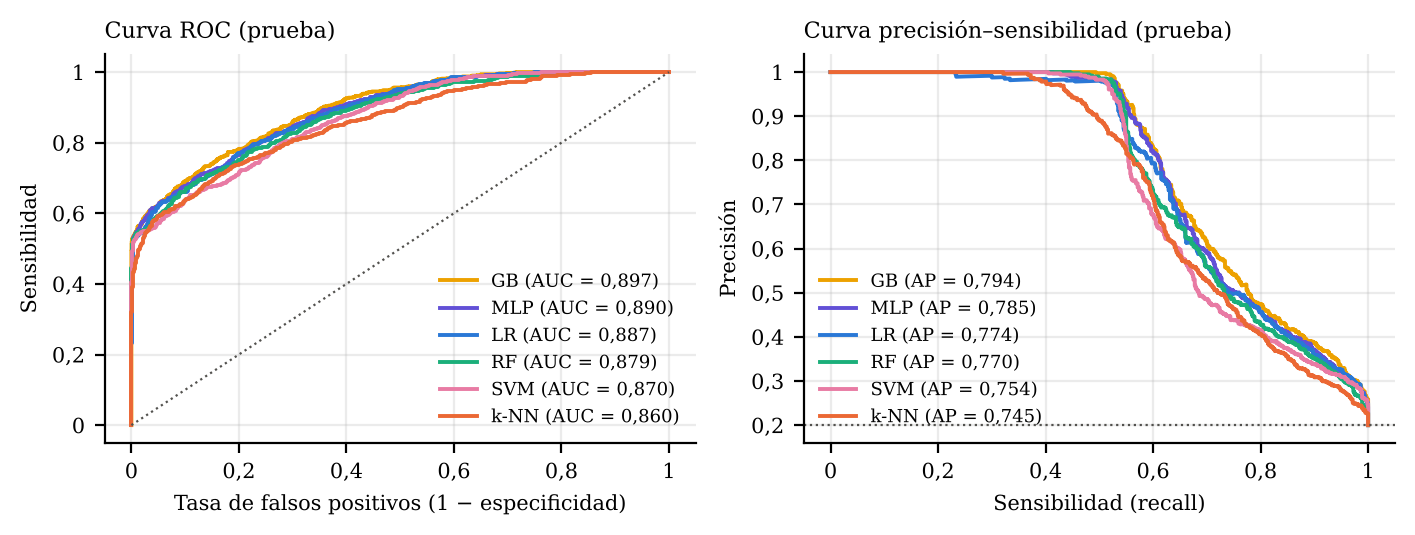

In [11]:
with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO2, 2.7))
    for nombre in orden:
        s = curvas_test[nombre]
        fpr, tpr, _ = roc_curve(yte, s); pr, rc, _ = precision_recall_curve(yte, s)
        axes[0].plot(fpr, tpr, color=COLOR[nombre], label=f"{nombre} (AUC = {coma(resumen.loc[nombre, 'AUC prueba'])})")
        axes[1].plot(rc, pr, color=COLOR[nombre], label=f"{nombre} (AP = {coma(resumen.loc[nombre, 'AP prueba'])})")
    axes[0].plot([0, 1], [0, 1], ':', color=GRIS, lw=0.8)
    axes[0].set_xlabel('Tasa de falsos positivos (1 − especificidad)'); axes[0].set_ylabel('Sensibilidad'); axes[0].set_title('Curva ROC (prueba)', loc='left')
    axes[1].axhline(yte.mean(), ls=':', color=GRIS, lw=0.8)
    axes[1].set_xlabel('Sensibilidad (recall)'); axes[1].set_ylabel('Precisión'); axes[1].set_title('Curva precisión–sensibilidad (prueba)', loc='left')
    axes[0].legend(loc='lower right'); axes[1].legend(loc='lower left')
    for ax in axes: ax.xaxis.set_major_formatter(FMT_COMA); ax.yaxis.set_major_formatter(FMT_COMA)
    fig.tight_layout(); fig.savefig('figs/fig6_roc_pr.png', dpi=300, bbox_inches='tight'); plt.show()

In [12]:
# Matriz de confusión en prueba del mejor modelo con el umbral elegido en validación
s = curvas_test[mejor_modelo]; u = resumen.loc[mejor_modelo, 'Umbral']
mc = pd.DataFrame(confusion_matrix(yte, (s >= u).astype(int)), index=['Real: pagó', 'Real: incumplió'], columns=['Pred.: pagó', 'Pred.: incumplió'])
mc.to_csv('resultados/matriz_confusion_mejor.csv')
print(f'Mejor modelo: {mejor_modelo} | umbral = {u:.3f}'); mc

Mejor modelo: GB | umbral = 0.200


,Pred.: pagó,Pred.: incumplió
Real: pagó,2779,421
Real: incumplió,221,579


## 6. Escenario B: ¿aportan algo `grade_subgrade`, `interest_rate` e `installment`?

Se reevalúa cada modelo con sus mejores hiperparámetros, agregando las tres variables excluidas (40 variables de entrada).

In [13]:
filas = []
for nombre, gs in busquedas.items():
    modelo_b = Pipeline([('prep', preprocesador(numericas_B)), ('clf', gs.best_estimator_.named_steps['clf'])])
    r = cross_validate(modelo_b, X_B.loc[idx_train], ytr, cv=cv, scoring='roc_auc', n_jobs=N_JOBS)['test_score']
    filas.append({'Modelo': nombre, 'AUC val. A (37 var.)': pliegues_auc[nombre].mean(), 'IC A': ic95(pliegues_auc[nombre]),
                  'AUC val. B (40 var.)': r.mean(), 'IC B': ic95(r), 'Dif. B − A': (r - pliegues_auc[nombre]).mean(),
                  'IC dif.': ic95(r - pliegues_auc[nombre])})
escenario_b = pd.DataFrame(filas).set_index('Modelo')
escenario_b.to_csv('resultados/escenario_B.csv')
escenario_b.round(4)

,AUC val. A (37 var.),IC A,AUC val. B (40 var.),IC B,Dif. B − A,IC dif.
Modelo,,,,,,
LR,0.8842,0.0057,0.8842,0.0056,0.0000,0.0001
k-NN,0.8542,0.0064,0.8545,0.0072,0.0003,0.0020
RF,0.8799,0.0050,0.8814,0.0057,0.0015,0.0020
GB,0.8934,0.0046,0.8932,0.0042,-0.0002,0.0007
SVM,0.8709,0.0057,0.8724,0.0058,0.0014,0.0016
MLP,0.8884,0.0056,0.8882,0.0064,-0.0002,0.0020


## 7. Resumen

- Los dos mejores modelos por AUC de validación se guardan en `resultados/mejores_modelos.json`; son los que se reevalúan con selección de variables, PCA y UMAP en `03_Reduccion_BlackLegend.ipynb`.
- Agregar las tres variables del escenario B no mejora el desempeño: no aportan información que no esté ya en `credit_score`, `loan_amount` y `loan_term`.

In [14]:
json.dump({'orden': orden, 'dos_mejores': orden[:2], 'umbrales': resumen['Umbral'].to_dict()}, open('resultados/mejores_modelos.json', 'w'), indent=2)
print('Dos mejores modelos:', orden[:2])

Dos mejores modelos: ['GB', 'MLP']
